1. Train Encoder
2. Train Decoder
3. Link Encoder to Decoder
4. Extract Embeddings and Apply to HSI Data
5. Use Decoder to Reconstruct Wavelength Data

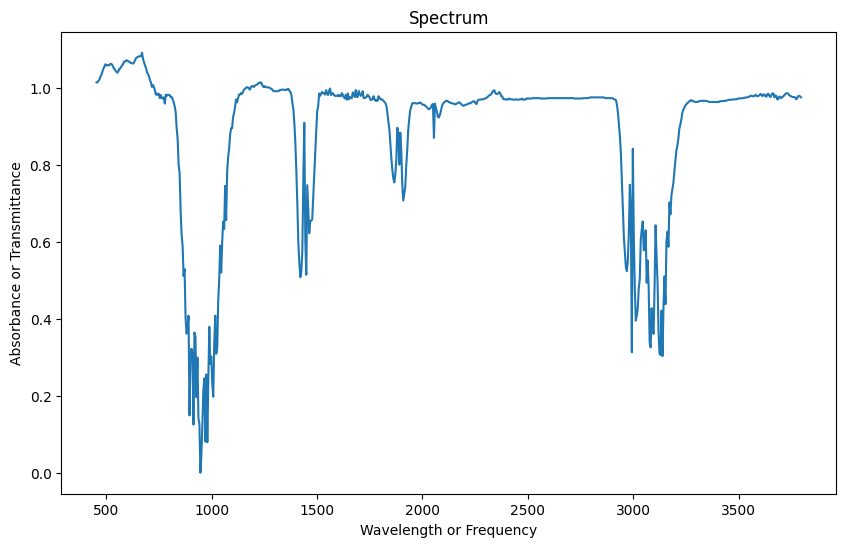

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def read_jdx(filename):
    """Simple function to read a JCAMP-DX file."""
    with open(filename, 'r') as file:
        lines = file.readlines()
    
    # Find start and end of data
    start = None
    end = None
    for i, line in enumerate(lines):
        if "##XYDATA=" in line or "##XYPOINTS=" in line:
            start = i + 1
        elif "##END=" in line:
            end = i
            break
    
    # Extract data
    x_data = []
    y_data = []
    if start is not None and end is not None:
        for line in lines[start:end]:
            parts = line.split()
            if len(parts) >= 2:
                try:
                    x_data.append(float(parts[0]))
                    y_data.append(float(parts[1]))
                except ValueError:
                    pass  
    
    return np.array(x_data), np.array(y_data)

x, y = read_jdx('../ref_data/74-85-1-IR.jdx')


plt.figure(figsize=(10, 6))
plt.plot(x, y)
plt.xlabel('Wavelength or Frequency')  
plt.ylabel('Absorbance or Transmittance') 
plt.title('Spectrum')
plt.show()
